# Cross-Benchmark Aggregate Ranking

Rank-based, scale-free, direction-aware aggregate alignment statistic across all three benchmarks.

**Approach**: rank each model per metric (ranks are scale-free), average the ranks.
Direction is handled per metric:
- **Point metrics** (Acc, AUC, $\kappa$; SAT steepness $K$): ranked by $|\text{value} - \text{NC}|$ (closeness to the human noise ceiling)
- **Relational metrics** ($r_{\text{RT}}$, NLL; SAT eRMSE, $\rho$): ranked by raw value with the correct direction (these already embed the human comparison)

Two-tier aggregation (only NRM spans all three benchmarks):
1. **RDM+SC** — models ranked by their performance on the choice/RT evaluations.
2. **SATBench** — models ranked by their performance on the speed–accuracy trade-off benchmark.
3. **NRM overall** — normalised rank across all three benchmarks.

In [1]:
import os
import sys
from pathlib import Path

import numpy as np
import pandas as pd
from scipy.stats import rankdata

ROOT = Path('..').resolve()
sys.path.insert(0, str(ROOT))

# results_io resolves every path from its own location, so this notebook works
# regardless of the kernel's working directory.
from scripts import results_io
from scripts.results_io import (
    METRIC_COLS, SAT_COLS, MissingResultsError,
    load_computed_nc, load_global_results, load_sat_results,
)

OUT = results_io.RANKING_DIR
OUT.mkdir(parents=True, exist_ok=True)
print(f'Reading results from {results_io.display_path(results_io.OUTPUTS)}')
print(f'Writing ranking to  {results_io.display_path(OUT)}')

Reading results from outputs
Writing ranking to  outputs/ranking


## Load Results

All values below are loaded directly from the files generated by the other notebooks in `pipelines/`:

| Source | File |
|---|---|
| `pipelines/rdm.ipynb` | `outputs/rdm/rdm_global_results.json` |
| `pipelines/sc.ipynb` | `outputs/sc/sc_global_results.json` |
| `pipelines/sat.ipynb` | `outputs/sat/<task>/nrm_metrics.json`, `outputs/sat/human_nc.json` |
| `competitors/<model>/train_sat.py` | `outputs/sat/<task>/<model>_metrics.json` |

If a file is missing the cell **fails with the name of the notebook to
run**.

In [2]:
rdm = load_global_results('rdm')
sc = load_global_results('sc')
sat = load_sat_results()

# The point metrics are ranked by closeness to the human noise ceiling, which
# the benchmark notebooks compute and write next to the model results.
def ceiling(benchmark):
    computed = load_computed_nc(benchmark)
    if computed is None:
        raise MissingResultsError(
            f'No human noise ceiling for {benchmark.upper()}. '
            f'Run {results_io.PRODUCER[benchmark]} first.')
    return {k: (np.nan if v is None else float(v)) for k, v in computed.items()}


rdm_nc = ceiling('rdm')
sc_nc = ceiling('sc')
sat_nc = ceiling('sat')

# How each metric is scored. "t1" = point metric, ranked by closeness to the
# human noise ceiling; "max"/"min" = relational metric, ranked on its raw value.
rdmsc_metric_kind = {
    'Acc': 't1', 'AUC': 't1', 'kappa': 't1',
    'r_RT': 'max', 'NLL': 'min',
}
sat_metric_kind = {
    c: ('t1' if c.endswith('_K') else ('min' if c.endswith('_RMSE') else 'max'))
    for c in SAT_COLS
}

for name, df in [('RDM', rdm), ('SC', sc), ('SAT', sat)]:
    n_missing = int(df.isna().sum().sum())
    note = f'  ({n_missing} missing cell(s))' if n_missing else ''
    print(f'{name:4s}: {len(df)} models — {list(df.index)}{note}')

print('\nRDM\n', rdm.round(3).to_string())
print('\nSC\n', sc.round(3).to_string())
print('\nSAT\n', sat.round(3).to_string())

RDM : 5 models — ['NRM', 'RTify', 'LNR', 'LBA', 'DDM']
SC  : 6 models — ['NRM', 'RTify', 'cRNN', 'LNR', 'LBA', 'DDM']
SAT : 6 models — ['NRM', 'CNet(par.)', 'CNet(ser.)', 'ConvRNN', 'MSDNet', 'SCAN']

RDM
          Acc    AUC  kappa   r_RT    NLL
NRM    0.794  0.924  0.585  0.989 -0.147
RTify  0.548  0.548  0.095  0.821 -0.067
LNR    0.482  0.482 -0.036 -0.547 -0.121
LBA    0.505  0.505  0.010  0.497 -0.117
DDM    0.501  0.502  0.003 -0.720 -0.122

SC
          Acc    AUC  kappa   r_RT    NLL
NRM    0.834  0.916  0.666  0.791 -0.301
RTify  0.786  0.873  0.562  0.791 -0.042
cRNN   0.611  0.627  0.240  0.713 -1.063
LNR    0.491  0.493 -0.015  0.493 -1.394
LBA    0.513  0.518  0.033  0.170 -1.353
DDM    0.509  0.507  0.013  0.357 -1.380

SAT
             CB_RMSE   CB_r   CB_K  CG_RMSE   CG_r   CG_K  GN_RMSE   GN_r   GN_K
NRM          30.669  0.282  0.722   24.320  0.415  0.829   29.735  0.123  0.434
CNet(par.)   31.723  0.415  1.764   27.185  0.434  1.696   35.476  0.199  1.115
CNet(ser.)

## Ranking Functions

In [3]:
def rank_column(values: pd.Series, kind: str, nc: float) -> np.ndarray:
    """Rank (1 = best) for one metric column.
    """
    v = values.to_numpy(dtype=float)
    if kind == 't1':
        if not np.isfinite(nc):
            raise ValueError(f'point metric {values.name!r} needs a noise ceiling')
        score = np.abs(v - nc)
    elif kind == 'min':
        score = v
    elif kind == 'max':
        score = -v
    else:
        raise ValueError(kind)

    out = np.full(len(v), np.nan)
    ok = np.isfinite(score)
    if ok.any():
        out[ok] = rankdata(score[ok], method='average')
    return out


def rank_table(df: pd.DataFrame, kinds: dict, nc: dict):
    """Ranks (1=best) and normalised ranks (0=best, 1=worst) per metric.

    Normalisation uses the number of models actually ranked in that column.
    """
    ranks = pd.DataFrame(index=df.index, columns=df.columns, dtype=float)
    norm = pd.DataFrame(index=df.index, columns=df.columns, dtype=float)
    for col in df.columns:
        r = rank_column(df[col], kinds[col], nc.get(col, np.nan))
        ranks[col] = r
        n_ranked = int(np.isfinite(r).sum())
        norm[col] = (r - 1.0) / (n_ranked - 1.0) if n_ranked > 1 else 0.0
    return ranks, norm

## Per-Benchmark Rankings

In [4]:
rdm_ranks, rdm_norm = rank_table(rdm, rdmsc_metric_kind, rdm_nc)
sc_ranks, sc_norm = rank_table(sc, rdmsc_metric_kind, sc_nc)
sat_ranks, sat_norm = rank_table(sat, sat_metric_kind, sat_nc)

for name, df, ranks, norm in [
    ("RDM", rdm, rdm_ranks, rdm_norm),
    ("SC", sc, sc_ranks, sc_norm),
    ("SATBench", sat, sat_ranks, sat_norm),
]:
    summary = pd.DataFrame({
        "mean_rank": ranks.mean(axis=1),
        "mean_norm_rank": norm.mean(axis=1),
    }).sort_values("mean_norm_rank")
    summary["place"] = np.arange(1, len(summary) + 1)
    print(f"\n{'=' * 60}")
    print(f"{name}: mean rank & normalised rank (n_models={len(df)})")
    print("=" * 60)
    print(summary.round(3).to_string())
    ranks.to_csv(os.path.join(OUT, f"ranking_{name.lower()}_ranks.csv"))
    summary.to_csv(os.path.join(OUT, f"ranking_{name.lower()}_summary.csv"))


RDM: mean rank & normalised rank (n_models=5)
       mean_rank  mean_norm_rank  place
NRM          1.8            0.20      1
RTify        2.4            0.35      2
LBA          3.0            0.50      3
DDM          3.6            0.65      4
LNR          4.2            0.80      5

SC: mean rank & normalised rank (n_models=6)
       mean_rank  mean_norm_rank  place
NRM          2.1            0.22      1
RTify        2.5            0.30      2
cRNN         3.2            0.44      3
LBA          4.2            0.64      4
DDM          4.4            0.68      5
LNR          4.6            0.72      6

SATBench: mean rank & normalised rank (n_models=6)
            mean_rank  mean_norm_rank  place
NRM             2.000           0.200      1
CNet(ser.)      2.778           0.356      2
CNet(par.)      3.444           0.489      3
SCAN            3.667           0.533      4
ConvRNN         4.111           0.622      5
MSDNet          5.000           0.800      6


## Tier 1 — RDM + SC Leaderboard (shared roster)

In [5]:
all_models = sorted(set(rdm_norm.index) | set(sc_norm.index))
rows = {}
for m in all_models:
    vals = []
    if m in rdm_norm.index:
        vals += list(rdm_norm.loc[m].values)
    if m in sc_norm.index:
        vals += list(sc_norm.loc[m].values)
    rows[m] = {
        "mean_norm_rank": np.mean(vals),
        "n_metrics": len(vals),
        "benchmarks": ("RDM+SC" if (m in rdm_norm.index and m in sc_norm.index)
                       else ("SC" if m in sc_norm.index else "RDM")),
    }
rdmsc_board = pd.DataFrame(rows).T.sort_values("mean_norm_rank")
rdmsc_board["place"] = np.arange(1, len(rdmsc_board) + 1)
print("\nTier 1 — RDM+SC Leaderboard (normalised ranks pooled)")
print("=" * 60)
print(rdmsc_board.round(3).to_string())
rdmsc_board.to_csv(os.path.join(OUT, "ranking_tier1_rdm_sc.csv"))


Tier 1 — RDM+SC Leaderboard (normalised ranks pooled)
      mean_norm_rank n_metrics benchmarks  place
NRM             0.21        10     RDM+SC      1
RTify          0.325        10     RDM+SC      2
cRNN            0.44         5         SC      3
LBA             0.57        10     RDM+SC      4
DDM            0.665        10     RDM+SC      5
LNR             0.76        10     RDM+SC      6


## Tier 2 — SATBench Leaderboard (separate roster)

In [6]:
sat_board = pd.DataFrame({
    "mean_norm_rank": sat_norm.mean(axis=1),
    "n_metrics": sat_norm.shape[1],
}).sort_values("mean_norm_rank")
sat_board["place"] = np.arange(1, len(sat_board) + 1)
print("\nTier 2 — SATBench Leaderboard (normalised ranks over 9 columns)")
print("=" * 60)
print(sat_board.round(3).to_string())
sat_board.to_csv(os.path.join(OUT, "ranking_tier2_sat.csv"))


Tier 2 — SATBench Leaderboard (normalised ranks over 9 columns)
            mean_norm_rank  n_metrics  place
NRM                  0.200          9      1
CNet(ser.)           0.356          9      2
CNet(par.)           0.489          9      3
SCAN                 0.533          9      4
ConvRNN              0.622          9      5
MSDNet               0.800          9      6


## Tier 3 — NRM Overall (only model evaluated on all three benchmarks)

In [7]:
BOARDS = [('RDM', rdm_norm), ('SC', sc_norm), ('SATBench', sat_norm)]

absent = [name for name, d in BOARDS if 'NRM' not in d.index]
if absent:
    raise MissingResultsError(
        f"NRM absent from {', '.join(absent)} results — rerun those pipelines."
    )

nrm_rdm = rdm_norm.loc['NRM'].mean()
nrm_sc = sc_norm.loc['NRM'].mean()
nrm_sat = sat_norm.loc['NRM'].mean()

overall_equal = np.mean([nrm_rdm, nrm_sc, nrm_sat])
overall_colwt = np.average(
    [nrm_rdm, nrm_sc, nrm_sat],
    weights=[rdm_norm.shape[1], sc_norm.shape[1], sat_norm.shape[1]],
)

print('\nNRM Overall Normalised Rank (0=best, 1=worst)')
print('=' * 60)
print(f'  RDM:                         {nrm_rdm:.3f}')
print(f'  SC:                          {nrm_sc:.3f}')
print(f'  SATBench:                    {nrm_sat:.3f}')
print(f'  Overall (equal weight):      {overall_equal:.3f}')
print(f'  Overall (col-weighted):      {overall_colwt:.3f}')

# Report the placement that was computed, rather than asserting it.
places = {}
print('\nNRM placement per benchmark (1 = best)')
print('=' * 60)
for name, norm_df in BOARDS:
    order = norm_df.mean(axis=1).sort_values()
    place = int(order.index.get_loc('NRM')) + 1
    places[name] = place
    print(f'  {name:10s} #{place} of {len(order)}')

if all(p == 1 for p in places.values()):
    print(f'\nNRM ranks #1 in all {len(places)} benchmarks, and is the only '
          f'model evaluated on all of them.')
else:
    off = {k: v for k, v in places.items() if v != 1}
    print(f'\nNRM is not #1 everywhere: {off}')


NRM Overall Normalised Rank (0=best, 1=worst)
  RDM:                         0.200
  SC:                          0.220
  SATBench:                    0.200
  Overall (equal weight):      0.207
  Overall (col-weighted):      0.205

NRM placement per benchmark (1 = best)
  RDM        #1 of 5
  SC         #1 of 6
  SATBench   #1 of 6

NRM ranks #1 in all 3 benchmarks, and is the only model evaluated on all of them.


## Visualisation

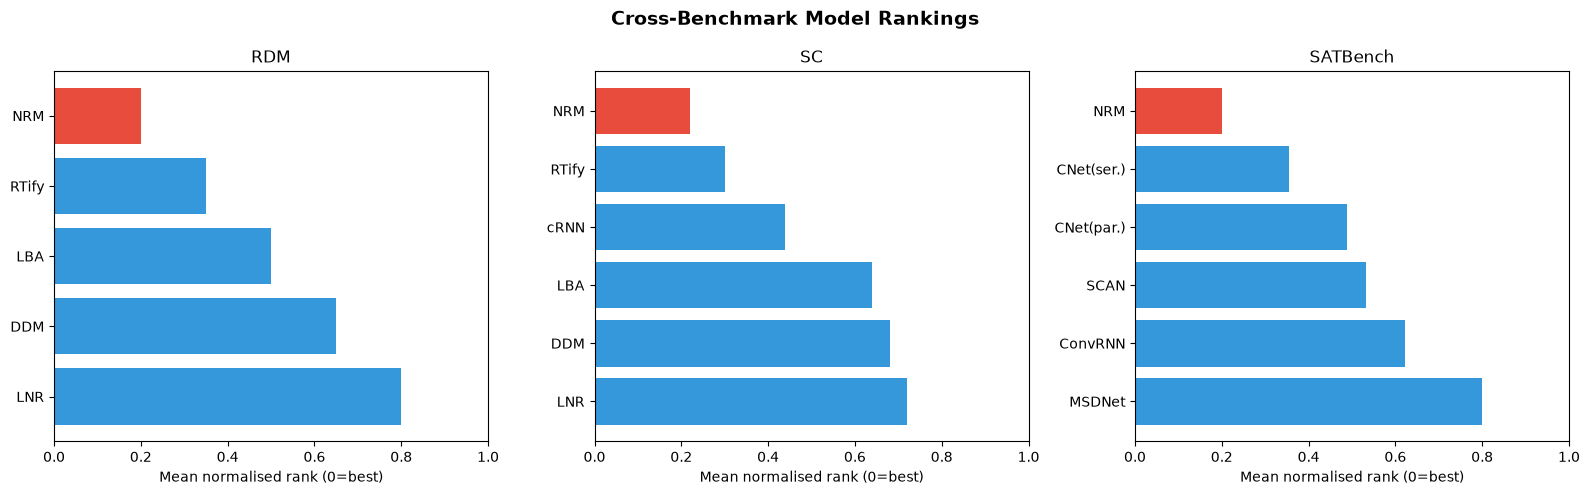

Saved to outputs/ranking/


In [8]:
import matplotlib.pyplot as plt

fig, axes = plt.subplots(1, 3, figsize=(16, 5))

for ax, (name, norm_df) in zip(axes, [
    ("RDM", rdm_norm), ("SC", sc_norm), ("SATBench", sat_norm),
]):
    mean_ranks = norm_df.mean(axis=1).sort_values()
    colors = ['#E74C3C' if m == 'NRM' else '#3498DB' for m in mean_ranks.index]
    bars = ax.barh(range(len(mean_ranks)), mean_ranks.values, color=colors)
    ax.set_yticks(range(len(mean_ranks)))
    ax.set_yticklabels(mean_ranks.index)
    ax.set_xlabel('Mean normalised rank (0=best)')
    ax.set_title(name)
    ax.set_xlim(0, 1)
    ax.invert_yaxis()

fig.suptitle('Cross-Benchmark Model Rankings', fontsize=14, fontweight='bold')
fig.tight_layout()
# Dropping /CreationDate keeps the PDF deterministic (see scripts/figures.py).
fig.savefig(os.path.join(OUT, 'ranking_overview.pdf'), bbox_inches='tight',
            dpi=300, metadata={'CreationDate': None})
plt.show()
print(f"Saved to {results_io.display_path(OUT)}/")